In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo gráfico para el reporte
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [3]:
# 1. Lectura del archivo CSV original
path_csv = "../data/raw/poblacion_atendida_hospital_general.csv"

# Aplicamos lectura controlada definiendo valores faltantes explícitos
df = pd.read_csv(
    path_csv,
    sep=",",
    encoding="utf-8",
    na_values=["", "NA", "N/A", "-", "null", "999"],
    skipinitialspace=True
)

# Imprimir dimensiones y resumen inicial
print(f"Número de filas: {df.shape[0]}")
print(f"Número de columnas: {df.shape[1]}")
print("\n--- Primeras 5 filas ---")
df.head()


Número de filas: 182700
Número de columnas: 12

--- Primeras 5 filas ---


C:\Users\Usuario 1\AppData\Local\Temp\ipykernel_12604\1671343725.py:5: DtypeWarning: Columns (0: codigo_aseguradora) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,año,periodo_reporte,fecha_atencion,servicio,sexo,codigo_aseguradora,aseguradora,poblacion,Departamento,edad,rango_edad,regimen
0,2022,1,2022-01-02T00:00:00.000-05:00,Ambulatorio,M,20002686.0,ALIANZA MEDELLIN ANTIOQUIA EPS SUBSIDIADO ISS ...,Veinte de Julio SAN JAVIER,ANTIOQUIA,2,1 - 4 aNos,REgimen Subsidiado
1,2022,1,2022-01-02T00:00:00.000-05:00,Ambulatorio,M,20000362.0,"AXA COLPATRIA SEGUROS SA, SOAT",Barrio Cristobal LA AMERICA,ANTIOQUIA,35,15 - 44 aNos,Otros
2,2022,1,2022-01-02T00:00:00.000-05:00,Ambulatorio,M,20000368.0,SEGUROS LA PREVISORA,Playon de Los Comuneros SANTA CRUZ,ANTIOQUIA,24,15 - 44 aNos,Otros
3,2022,1,2022-01-02T00:00:00.000-05:00,Ambulatorio,M,20000366.0,SEGUROS DEL ESTADO,Aures No2 ROBLEDO,ANTIOQUIA,23,15 - 44 aNos,Otros
4,2022,1,2022-01-02T00:00:00.000-05:00,Hospitalizado,M,20000368.0,SEGUROS LA PREVISORA,MEDELLIN,ANTIOQUIA,32,15 - 44 aNos,Otros


In [4]:
# --- ETAPA 2: PARSEO DE DATOS ---

# 1. Parseo de Fecha a formato datetime
df['fecha_atencion'] = pd.to_datetime(df['fecha_atencion'], errors='coerce')

# 2. Normalización de textos (evitar que 'Ambulatorio' y 'AMBULATORIO' se cuenten por separado)
cols_texto = ['servicio', 'sexo', 'Departamento', 'regimen', 'aseguradora']
for col in cols_texto:
    df[col] = df[col].astype(str).str.strip().str.upper()

# 3. Corrección de errores de codificación en rangos de edad ('aNos' -> 'años')
df['rango_edad'] = (
    df['rango_edad']
    .astype(str)
    .str.replace('aNos', 'años', regex=False)
    .str.replace('aNo', 'año', regex=False)
    .str.strip()
)

# 4. Asegurar tipo numérico en la variable edad
df['edad'] = pd.to_numeric(df['edad'], errors='coerce')

print("¡Parseo de tipos completado exitosamente!")
df.dtypes

¡Parseo de tipos completado exitosamente!


año                                       int64
periodo_reporte                           int64
fecha_atencion        datetime64[us, UTC-05:00]
servicio                                    str
sexo                                        str
codigo_aseguradora                       object
aseguradora                                 str
poblacion                                   str
Departamento                                str
edad                                      int64
rango_edad                                  str
regimen                                     str
dtype: object

In [5]:
# --- ETAPA 3: DEPURACIÓN Y AUDITORÍA ---

# Reporte formal de auditoría de variables
reporte = pd.DataFrame({
    "Tipo_Dato": df.dtypes.astype(str),
    "N_Faltantes": df.isna().sum(),
    "%_Faltantes": (df.isna().mean() * 100).round(2),
    "Valores_Unicos": df.nunique(dropna=False)
})

print("=== REPORTE DE AUDITORÍA DE DATOS ===")
display(reporte)

print(f"\nFilas duplicadas idénticas: {df.duplicated().sum()}")
print(f"Edades fuera de rango biológico (< 0 o > 115): {((df['edad'] < 0) | (df['edad'] > 115)).sum()}")

=== REPORTE DE AUDITORÍA DE DATOS ===


,Tipo_Dato,N_Faltantes,%_Faltantes,Valores_Unicos
año,int64,0,0.00,2
periodo_reporte,int64,0,0.00,4
fecha_atencion,"datetime64[us, UTC-05:00]",0,0.00,673
servicio,str,0,0.00,2
sexo,str,0,0.00,2
codigo_aseguradora,object,3295,1.80,628
aseguradora,str,2564,1.40,262
poblacion,str,0,0.00,7093
Departamento,str,114,0.06,44
edad,int64,0,0.00,104



Filas duplicadas idénticas: 7147
Edades fuera de rango biológico (< 0 o > 115): 0


Porcentaje de atención a población femenina: 69.14%


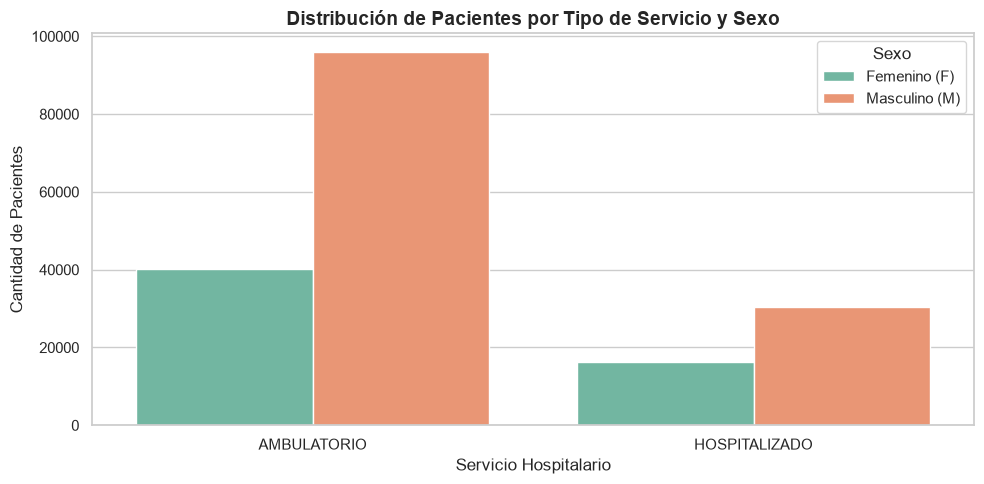

In [ ]:
#SEXO#
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x="servicio", hue="sexo", palette="Set2")

plt.title("Distribución de Pacientes por Tipo de Servicio y Sexo", fontsize=14, fontweight='bold')
plt.xlabel("Servicio Hospitalario", fontsize=12)
plt.ylabel("Cantidad de Pacientes", fontsize=12)
plt.legend(title="Sexo", labels=["Femenino (F)", "Masculino (M)"])

# Porcentaje de población femenina
femenino_pct = (df['sexo'] == 'F').mean() * 100
print(f"Porcentaje de atención a población femenina: {femenino_pct:.2f}%")

plt.tight_layout()
plt.show()

In [5]:
# Unificación de texto a mayúsculas y sin espacios adicionales
df['servicio'] = df['servicio'].astype(str).str.strip().str.upper()
df['sexo'] = df['sexo'].astype(str).str.strip().str.upper()

In [ ]:
# EXPORTAR DATASET LIMPIO Y PROCESADO ---
import os

ruta_base = os.path.abspath(os.path.join(os.getcwd(), ".."))
path_processed = os.path.join(ruta_base, "data", "processed", "poblacion_atendida_limpia.csv")

# Exportamos sin el índice
df.to_csv(path_processed, index=False)
print("¡Dataset limpio exportado con éxito en 'data/processed/poblacion_atendida_limpia.csv'!")

¡Dataset limpio exportado con éxito en 'data/processed/poblacion_atendida_limpia.csv'!


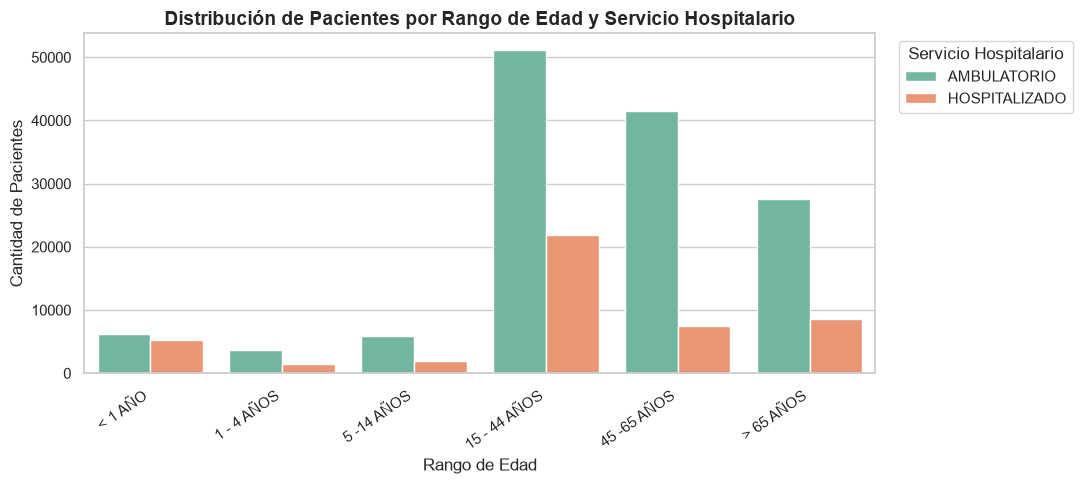

In [ ]:
##EDAD##
orden_cronologico = ['< 1 AÑO', '1 - 4 AÑOS', '5 -14 AÑOS', '15 - 44 AÑOS', '45 -65 AÑOS', '> 65 AÑOS']

plt.figure(figsize=(11, 5))

ax = sns.countplot(
    data=df, 
    x="rango_edad", 
    hue="servicio", 
    palette="Set2",
    order=orden_cronologico
)

plt.title("Distribución de Pacientes por Rango de Edad y Servicio Hospitalario", fontsize=14, fontweight='bold')
plt.xlabel("Rango de Edad", fontsize=12)
plt.ylabel("Cantidad de Pacientes", fontsize=12)
plt.xticks(rotation=35, ha='right')

# Posicionamos la leyenda fuera del área del gráfico para evitar que tape las barras
plt.legend(title="Servicio Hospitalario", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [16]:
# Parseo departamento#
df['Departamento'] = df['Departamento'].astype(str).str.strip().str.upper()

C:\Users\Usuario 1\AppData\Local\Temp\ipykernel_12604\4266585508.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


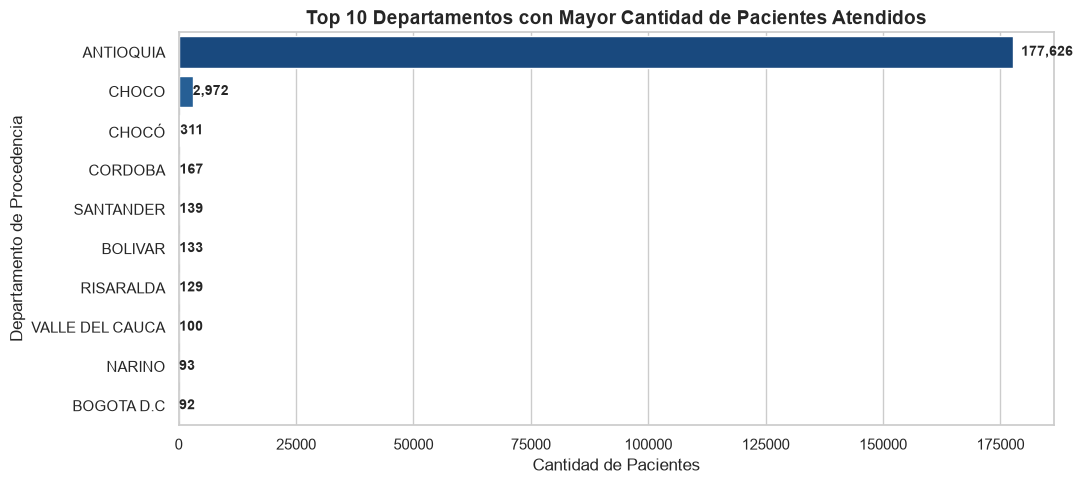

Porcentaje de atención a pacientes de Antioquia: 97.22%
Porcentaje de atención a pacientes foráneos: 2.78%


In [17]:
# Departamento#

top_deptos = df['Departamento'].value_counts().head(10)

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    x=top_deptos.values, 
    y=top_deptos.index, 
    palette="Blues_r"
)

plt.title("Top 10 Departamentos con Mayor Cantidad de Pacientes Atendidos", fontsize=14, fontweight='bold')
plt.xlabel("Cantidad de Pacientes", fontsize=12)
plt.ylabel("Departamento de Procedencia", fontsize=12)

# Agregar las etiquetas de valor exacto al final de cada barra
for index, value in enumerate(top_deptos.values):
    ax.text(value + (value * 0.01), index, f'{value:,}', va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# Imprimir distribución porcentual
pct_antioquia = (df['Departamento'] == 'ANTIOQUIA').mean() * 100
print(f"Porcentaje de atención a pacientes de Antioquia: {pct_antioquia:.2f}%")
print(f"Porcentaje de atención a pacientes foráneos: {100 - pct_antioquia:.2f}%")

In [ ]:
## Modelo de predicion ###

